In [2]:
from langchain_google_genai import ChatGoogleGenerativeAI

import os 
from dotenv import load_dotenv
# This function will load all the variables from .env file into the environment
# make them available to in the os.environ dictionary
load_dotenv()   

if os.environ.get("GOOGLE_API_KEY"):
    print ("GOOGLE_API_KEY found in the environment variables")
else:
    raise ValueError ("GOOGLE_API_KEY not found in the environment variables")


from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage

# for the string out praser 
from langchain_core.output_parsers import StrOutputParser


llm_gemini = ChatGoogleGenerativeAI(model="gemini-2.0-flash", temperature=0)

GOOGLE_API_KEY found in the environment variables


In [3]:
#llm_gemini.invoke("hey, what is my name ?") refer the work file 

# **TOOLS**

In [4]:
# Tool -1 [news search Tool ]
#let's say your user want some news for that tool for that we use the duck duck go search 
# if we use the duck duck go search it is free and we don't need a api key but for some other news we need api key  
# it is duck duck go is very well integrated 
# the duck duck go is standalone service if we go to there website and we can see how we can use it as an API with python function 

# Tool -1 [news search Tool :duck duck go  ]

from langchain_community.tools import  DuckDuckGoSearchRun

search_tool = DuckDuckGoSearchRun( description=" This is a tool to search web for the news")

# Tool -2 [Wikipedia search tool ]

from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper


wiki_wrapper = WikipediaAPIWrapper()
wikipedia_tool = WikipediaQueryRun(api_wrapper=wiki_wrapper ,description=" This is a tool to search Wikipedia")

# we need to insall the Wikipedia with uv add Wikipedia 

# Tool -3 [custom tool ][Custom tool is a tool that we can create our own tool ]
#[Custom Enterprise tool ]

from langchain_core.tools import tool

@tool # decorator means it is a tool and decorator is a function that takes a function and returns a function
def enterprise_tool(query:str) -> str: # this function simply send an email to the user 
    """send an email to the user"""
    return "Email send " # in this we need to replace the email sending code with gamil api other things
    #Important : 
    # whenever we are creating your custom function we need to add a dock string. 
    #dock string is a string that is added to the function to describe the function 
    #dock string is kind of way to add comments in your function 
    # example """send an email to the user""" like this we simple provide the description of the function
    # we simply add a kind of message so that LLM can read because we have to tell this is an information this tool is built for this purpose 
   # 
    #why:
    # we need to add a dock string because we need to tell the LLM that this tool is built for this purpose 
    
    



❌ The exact error line (what failed)
wikipedia_tool = WikipediaQueryRun(api_wrapper=WikipediaAPIWrapper)

🧠 What Python + LangChain thought you meant

You passed a class, not an object.

So internally LangChain tried to do something like:

WikipediaAPIWrapper.get("Artificial Intelligence")


But…

👉 get() exists on the object, not on the class
👉 So Python throws:

AttributeError: get

✅ The correct line (what it expects)
wikipedia_tool = WikipediaQueryRun(
    api_wrapper=WikipediaAPIWrapper()
)


Notice the parentheses () 👀
That’s the entire difference.

🧩 One golden rule (remember this forever)

🔴 If a library expects something it will CALL methods on → you must pass an INSTANCE, not a CLASS

Or even shorter:

If you see .run() or .get() errors → check if you forgot ()

🧪 Memory trick (very important)
❌ Class (blueprint)
WikipediaAPIWrapper

✅ Object (usable thing)
WikipediaAPIWrapper()


LangChain tools always want the usable thing.

In [5]:
# here 'search" is insteaf for that 
#search.invoke("location of mvit colleage in puducherry in map")
# here we need to install the langchain_community with uv add langchain_community

# we got this error : Could not import ddgs python package. Please install it with `pip install -U ddgs`.
# so we install the uv pip install ddgs 
# ddgs is the 'duckduckgo-search' Python library that provides the underlying API for DuckDuckGo search functionality.

# output : 
#"The Manakula Vinayagar Institute of Technology, Pondicherry was established in the year 2008 and accredited by NAAC with an'A' grade. The MVIT Pondicherry is recognised by the University Grants Commission and approved by AICTE. The college is affiliated to the Pondicherry University, Puducherry . The MVIT Pondicherry Institute offers 3 Degrees and 12 Courses which includes B.Tech, M.Tech and MBA. mvit_pondicherry, Pondicherry. 698 likes · 2 talking about this · 108 were here. Manakula Vinayagar Institute of Technology, with its motto, Educate, Empower and Excel, has risen to MVIT - Top Engineering College in Pondicherry An epicenter of MVIT is served by eminent personalities from ex-corporate as well as academicians from top notch institutes .The Placement Cell ... Established in the year 1984, Puducherry Technological University in Kalapet,Pondicherry listed under Chemical Engineering Colleges in Pondicherry. Rated 4.1 based on 1009 Customer Reviews and Ratings with 14 Photos. Visit Justdial for Address, Contact Number, Reviews & Ratings, Photos, Maps of Puducherry Technological University, Kalapet, Pondicherry. MVIT Pondicherry: Admission 2026, Cutoff, Courses, Fees, Placements, Ranking Puducherry , Puducherry 3.3/5 (2) 2 Que. & Ans PrivateAffiliated College of Pondicherry University, Puducherry Enquire Brochure Course List"
 # but why it don't show the correct location 

wikipedia_tool.invoke("what is the capital of France?")    

'Page: Closed-ended question\nSummary: A closed-ended question is any question for which a researcher provides research participants with options from which to choose a response. Closed-ended questions are sometimes phrased as a statement that requires a response.\nA closed-ended question contrasts with an open-ended question, which cannot easily be answered with specific information.\n\n\n\nPage: What Is a Nation?\nSummary: "What Is a Nation?" (French: Qu\'est-ce qu\'une nation ?) is an 1882 lecture by French historian Ernest Renan (1823–1892) at the Sorbonne, known for the statements that a nation is "a daily plebiscite", and that nations are based as much on what people jointly forget as on what they remember.  It is frequently quoted or anthologized in works of history or political science pertaining to nationalism and national identity. It exemplifies   a contractualist understanding of the nation.\n\nPage: France\nSummary: France, officially the French Republic, is a country prim

IN this above output is not generated by AI . that is tool call that means we made a tool call to duck go search run . in the above we basically a news we want to get some news some information regarding this question "location of mvit colleage in puducherry in map" so this answer is response of this particular function called duck duck go search run on .this is not generated by LLM 

we will bind this tool to LLM so that it can make the use of this function but currently it is not connected to LLM 

the output is simply the response getting from the duck duck go search 

# **we going to create a toolkits**

In [6]:
# in this toolkit we will write all the function mean tool 

toolkit = [search_tool, wikipedia_tool,enterprise_tool]

In [7]:
# we can list the tools we have in toolkit 

toolkit

[DuckDuckGoSearchRun(description=' This is a tool to search web for the news', api_wrapper=DuckDuckGoSearchAPIWrapper(region='wt-wt', safesearch='moderate', time='y', max_results=5, backend='auto', source='text')),
 WikipediaQueryRun(description=' This is a tool to search Wikipedia', api_wrapper=WikipediaAPIWrapper(wiki_client=<module 'wikipedia' from 'c:\\Users\\acer\\Desktop\\Langchain_tutorial\\.venv\\Lib\\site-packages\\wikipedia\\__init__.py'>, top_k_results=3, lang='en', load_all_available_meta=False, doc_content_chars_max=4000)),
 StructuredTool(name='enterprise_tool', description='send an email to the user', args_schema=<class 'langchain_core.utils.pydantic.enterprise_tool'>, func=<function enterprise_tool at 0x0000026F1FA49D00>)]

# **ReAct Agent**

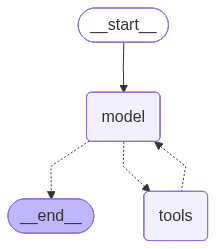

In [8]:
from langchain.agents import create_agent 


from langchain_google_genai import ChatGoogleGenerativeAI


# Gemini model
model = ChatGoogleGenerativeAI(
    model="gemini-2.0-flash",
    temperature=0.7,
    max_output_tokens=1000,
    timeout=30
)
agent = create_agent(
    model,
    tools=toolkit)
agent
    

in this _start_ and _end_ is saying that start is staring part and _end_ is end part and above diagram is similar to the diagram in words.


now we going to test the agent we build now we want to invoke the agent but we will invoke it using streaming .
what is streaming :
Streamin means when we just display or baiscally use a data  as soon as it arrives . so when we will be just making this model call there will be so many things running in the backend in background ans we want to aslo visualize this and we also  want to see "what are the things going on in the background . so we will be using streaming so that we can see eveything what's going on 
   

# **ReAct Agent invoke with Streams**

In [9]:
example_query ="Give me the lasted news about the stock market for today"
events = agent.stream(
    {"messages":[("user",example_query)]},
    stream_mode="values" # becauase we use the stream mode = values it will return the events # purpose of stream mode is to return the events
) # becasue we are using stream  and message here indicate the user query 

for event in events:
   event["messages"][-1].pretty_print() # explain this line 

================================ Human Message =================================

Give me the lasted news about the stock market for today
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_search (ef4c928f-6846-4c75-a469-e897fcad2a31)
 Call ID: ef4c928f-6846-4c75-a469-e897fcad2a31
  Args:
    query: stock market news today
================================= Tool Message =================================
Name: duckduckgo_search

Stock Market Today , Jan. 23: Stocks mixed after Intel's disappointing earnings Stocks have an opportunity to finish the week on strong footing after a rough start Jan 23, 2026 5:50 PM EST Stock Market Today : The Dow Jones index slid Friday despite a rise in Nvidia. Small caps sold off after hitting a high on Thursday. Our real-time stock market news feed automatically updates to show the latest 50 breaking market alerts. Stock Titan offers instant market updates for GOLD/PLATINUM users, 30-second delay for

we github i has more ouptut but it given only one why : 

In [13]:
example_query = "Give me the lasted news about the stock market for today"

events = agent.stream(
    {"messages": [("user", example_query)]},
    stream_mode="values",
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

Give me the lasted news about the stock market for today
================================== Ai Message ==================================
Tool Calls:
  duckduckgo_search (11c848d1-fb67-469e-9002-90c46917a128)
 Call ID: 11c848d1-fb67-469e-9002-90c46917a128
  Args:
    query: stock market news today
================================= Tool Message =================================
Name: duckduckgo_search

News . Latest. Originals. Newsletters. Stock market . Stock market today : Dow, S&P 500, Nasdaq slip, chip stocks rise as Wall Street ends volatile week lower. Get stock market quotes, personal finance advice, company news and more. Stock market data coverage from CNN. View US markets , world markets , after hours trading, quotes, and other important stock market activity. Today 's hot stocks . Where the world charts, chats, and trades markets . We're a supercharged super-charting platform and social network

# **Manually Binding the LLM with Tools**

In [11]:
#without binding 
llm_gemini.invoke("what is lasted news about the stock market")

AIMessage(content="Here's a quick rundown of the latest stock market news:\n\n*   **Recent Performance:** The stock market has been experiencing some volatility recently. The major indexes, including the S&P 500, Dow Jones Industrial Average, and Nasdaq Composite, have seen fluctuations due to various economic factors.\n*   **Key Drivers:** Several factors are influencing the market, including:\n    *   **Inflation Data:** Recent inflation reports are closely watched by investors.\n    *   **Interest Rate Expectations:** The Federal Reserve's monetary policy and potential interest rate hikes are major drivers.\n    *   **Economic Growth:** Overall economic growth data, including GDP and employment figures, impacts market sentiment.\n    *   **Corporate Earnings:** Earnings reports from major companies provide insights into the health of the economy and individual sectors.\n*   **Sector Performance:** Some sectors are performing better than others. Technology, energy, and healthcare are

In [12]:
#wiht binding :
llm_binded = llm_gemini.bind_tools(toolkit)

llm_binded.invoke("what is lasted news about the stock market")

AIMessage(content='', additional_kwargs={'function_call': {'name': 'duckduckgo_search', 'arguments': '{"query": "stock market news"}'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.0-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019bf480-1a1e-74d3-9fb2-ef21b231a0d5-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'stock market news'}, 'id': 'dd4399c6-54f5-4702-8269-9a0f8cbdac70', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 63, 'output_tokens': 9, 'total_tokens': 72, 'input_token_details': {'cache_read': 0}})

AIMessage(content='', additional_kwargs={'function_call': {'name': 'duckduckgo_search', 'arguments': '{"query": "stock market news"}'}}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-2.0-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--019bf138-8906-70c2-b593-860caa03d834-0', tool_calls=[{'name': 'duckduckgo_search', 'args': {'query': 'stock market news'}, 'id': 'e04cc60f-8083-4ee8-94a8-75cc17d65821', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 63, 'output_tokens': 9, 'total_tokens': 72, 'input_token_details': {'cache_read': 0}})

in this we have the tool call  that binding model with tool call with the tool 

this is **exactly** the kind of concept worth saving in your notes.

Below is **clean, ready-to-paste Markdown content** you can keep for future reference.

---

````markdown
# 🔍 Tool-Calling Behavior Difference: Gemini vs GPT (LangChain / LangGraph)

## 📌 Observation
When using tools (e.g., DuckDuckGo search) inside an agent:
- **Gemini models** usually generate **one tool call**
- **GPT models** often generate **multiple tool calls** for the same user query

This is **expected behavior**, not an error.

---

## 🧠 Core Reason: Tool Planning Strategy

Different LLMs use different internal strategies to decide **how many tools to call** and **how to break down a task**.

---

## 🤖 Gemini Tool Strategy (Minimalist Planner)

**Behavior**
- Makes **one broad tool call**
- Uses internal reasoning to summarize results
- Optimized for speed and fewer API calls

**Example**
```json
{
  "name": "duckduckgo_search",
  "args": {
    "query": "stock market news"
  }
}
````

**Assumption**

> One general search is enough to answer the question.

---

## 🤖 GPT Tool Strategy (Decompositional Planner)

**Behavior**

* Breaks the task into **multiple sub-queries**
* Calls the same tool multiple times
* Aggregates results before answering

**Example**

```json
[
  { "query": "stock market news today" },
  { "query": "S&P 500 today" },
  { "query": "Dow Jones Industrial Average news today" }
]
```

**Assumption**

> More specific searches → more accurate and complete answer.

---

## 📭 Why `content=""` in AIMessage?

When an `AIMessage` contains `tool_calls`:

* `content` is intentionally empty
* The model is saying:

  > "Call the tool(s) first. I will answer after."

This represents a **tool-planning step**, not the final response.

---

## 🔄 Agent Execution Flow

```
User Message
   ↓
AIMessage (tool_calls, content="")
   ↓
Tool Execution
   ↓
ToolMessage (results)
   ↓
AIMessage (final answer with content)
```

---

## ⚖️ Which Is Better?

| Model  | Best For                                    |
| ------ | ------------------------------------------- |
| Gemini | Fast responses, fewer API calls, lower cost |
| GPT    | Detailed analysis, multi-angle coverage     |

---

## 🎯 Key Takeaway

> **Different models plan tools differently.**
>
> * Gemini prefers **single-shot search**
> * GPT prefers **multi-step decomposition**

Both behaviors are correct and model-specific.

---

## 🛠️ Advanced Note

You can influence tool behavior using system prompts, e.g.:

```text
Break the query into multiple sub-queries and search each separately.
```

---

## ✅ Final Reminder

This behavior is:

* ❌ NOT a LangChain bug
* ❌ NOT a streaming issue
* ✅ A model-level reasoning and planning difference

```

---

If you want, next I can help you write:
- a **“LangGraph Debugging Notes” markdown**
- a **Tool Calling Cheatsheet**
- or a **Model Comparison table for interviews / HackQuest**

Just tell me 
```


In this video it comes with lasted modle chatgpt-5-mini so the LLM return the tool calls . 
# **now** what we we do manually  like langchain is doing it automatically but we do manually  we take the list of tool because it can have only one tool or it can have like a list of tools 

We take the list of tool and we make the function call one by one and we keep one updating that particular response with the message type called tool message 

In  this output stream we see a tool message we do it manually in langraph but in langchain is doing it automatically that's why langchain is a lightweight ai agent builder because we do not manage it anything . Everyting is done for you from the agentic point of view but from the branching and branching is less compare to langraph in agentic point of view 
